# 4. From steady-state to dynamic model

## 4.2 A look back at the previous chapter's results



Loading model from \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\input\example_weather.csv
Simulation started at time (ISO format): 2026-08-14T15:16:09.153904
Running: 100.00%

Simulation complete at time (ISO format): 2026-08-14T15:16:09.162836
Simulated 0.9965277777777778 days
Elapsed time: 0.00893259048461914 seconds
Output saved to file \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_1516.csv
Model structure log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_1516_model_struct_log.json
Simulation log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_15

NameError: name 'np' is not defined

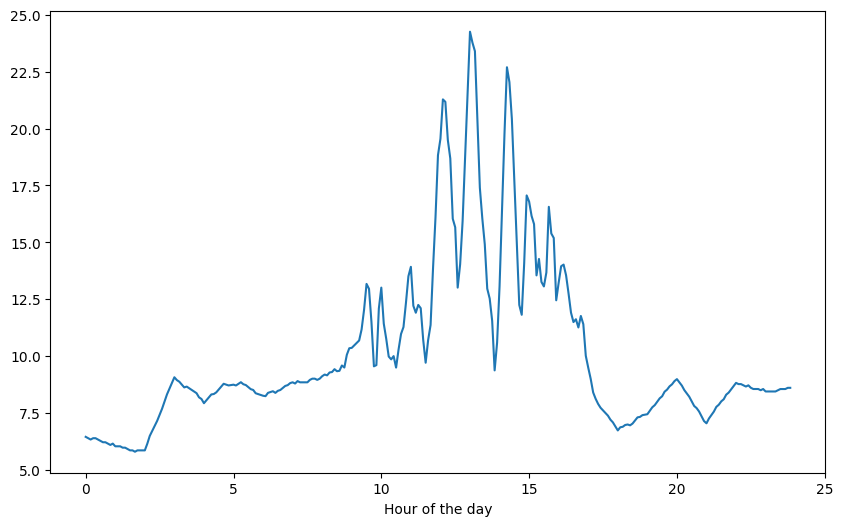

In [2]:
""" 
Imports needed for running the code
"""

# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is easier to just ignore them
import warnings
warnings.filterwarnings("ignore")

# For browsing for files in the operating system
import os



# For editing model output as DataFrames
import pandas as pd

# For displaying DataFrames
from IPython.display import display

# For making plots
import matplotlib.pyplot as plt

# For using the GreenLight platform
import greenlight

def display_graphs(full_sol, vars_to_plot, title, ylabel, line_style):
    """
    Display multiple graphs generated from a model solution full_sol

    :param full_sol: A full_sol attribute of a GreenLight instance, after the model has been run
    :chosen_vars: A list of variable names in full_sol to be displayed in the graph
    :title: The title to show on top of the graph
    :ylabel: The label to show on the y axis
    :line_style: The style of the lines. 
                 Use '-' for full lines, '--' for dashed, 
                 '-o' for full with circles showing the values  
    """
    # Create a new matplotlib figure
    plt.figure(figsize=(10, 6))

    # Plot each variable in the graph
    for var in vars_to_plot:
        plt.plot((full_sol["Time"]/3600)%24, full_sol[var], line_style, label=var)

    # Add axis labels, title, legend, grid 
    plt.xlabel("Hour of the day")
    plt.xticks(np.arange(0, 25, step=1))
    plt.xlim([0, 24])
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

""" 
Solution 3.2.2
Define a tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2 & Table 3.1",
        "definition": "0.8",
        "type": "const"
    },
    "iSun": {
        "name": "iSun",
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5 & pg. 70",
        "definition": "0.5",
        "type": "const"
    },
    "epsilonCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3 & Section 3.2.1",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6 & paragraph following",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5 & pg. 70",
        "definition": "0.5",
        "type": "const"
    },
    "epsilonSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3 & Section 3.2.1",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "4",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "4",
        "type": "const"
    }
}

"""
Add the variable tTunnel to the tunnel model definition tunnel_def
"""
tunnel_def["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsilonCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsilonSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsilonCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsilonSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

# Point to the location of the weather file, using the local operating system logic
weather_file = os.path.abspath(os.path.join("input", "example_weather.csv"))

# Set model options
options = {
    "options": {
        "t_start":"0",  # Start reading the input data at time point 0
        "t_end": str(16 * 86400),  # Stop reading the input data at day 16 (86400 = seconds in a day)
        "t_eval": "300",  # Calculate variables in 5 minute intervals
        "output_step": "300"  # Create output with 5 minute intervals
    }
}

tunnel_def["dummy"] = {
        "description": "Dummy variable",
        "unit": "-",
        "reference": "Used to get the model going",
        "type": "state",
        "definition": "0",
        "init": "0"
    }

# Set model options
options = {
    "options": {
        "t_start":str(15 * 86400),  # Start reading the input data at day 15
        "t_end": str(16 * 86400),  # Stop reading the input data at day 16 (86400 = seconds in a day)
        "t_eval": "300",  # Calculate variables in 5 minute intervals
        "output_step": "300"  # Create output with 5 minute intervals
    }
}

# Create a new instance of GreenLight
# input_prompt includes weather_file and options
mdl_3 = greenlight.GreenLight(
    input_prompt=[tunnel_def, weather_file, options], 
    )

mdl_3.run()

# Graph the simulated temperatures
display_graphs(mdl_3.full_sol, ["tTunnel"],"tTunnel", "°C", '-')

## 4.1 Imports for Chapter 3

The following code block defines imports that will be used later in this notebook. There's no need to read through this code, simply run it and move to the next section

In [1]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is not important
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

## 4.2 A look back at the previous chapter's results

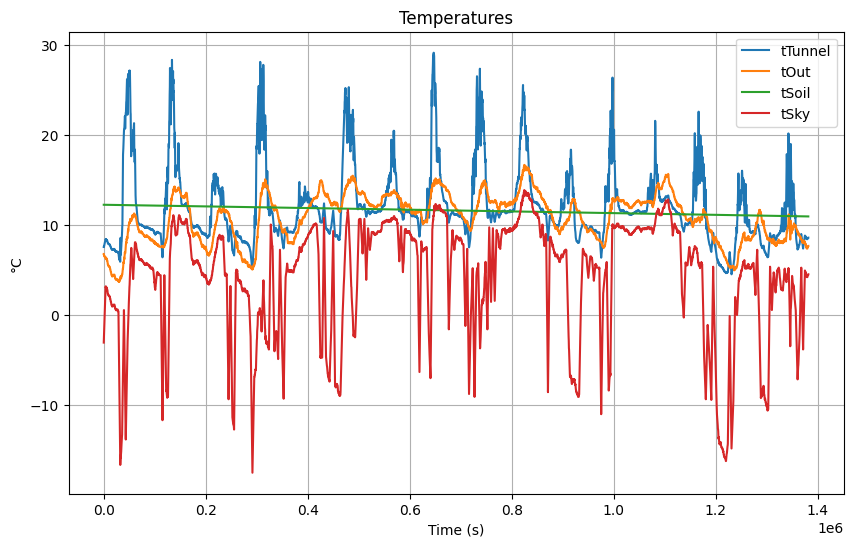

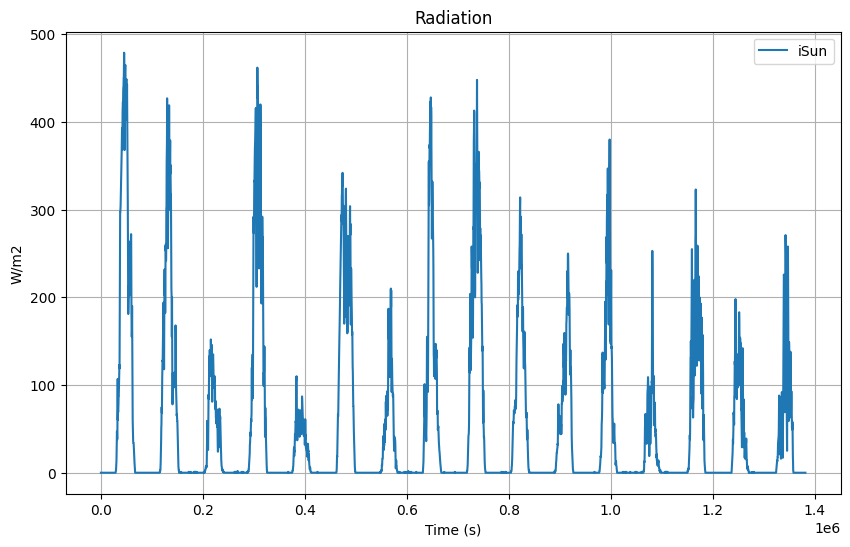

In [39]:
"""
Make graphs
"""

def display_output(output_df, chosen_vars, titles, ylabels, line_style):
    axes = []
    
    for vars_to_plot, title, ylabel in zip(chosen_vars, titles, ylabels):
        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111)
        
        for var in vars_to_plot:
            ax.plot(output_df["Time"], output_df[var], line_style, label=var)
        
        ax.set_xlabel("Time (s)")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        axes.append(ax)
        plt.show()

    return axes
        

def model_table(mdl):
    var_types = {}
    for var in mdl.variables.keys():
        if var in mdl.states.keys():
            var_types[var] = "state"
        elif var in mdl.aux.keys():
            var_types[var] = "aux"
        elif var in mdl.inputs.keys():
            var_types[var] = "input"
        elif var in mdl.consts.keys():
            var_types[var] = "const"
        else:
            var_types[var] = "none"

    df = pd.DataFrame({"Type": var_types, "Definition": mdl.variables}).rename_axis("Variable").reset_index()
    display(df.style
                .hide(axis="index")
                .set_properties(**{"text-align": "left", "font-family": "monospace"})
                .set_table_styles([
                    {"selector": "th", "props": [("text-align", "left")]}
              ])
        )

# Load simulation result
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

# Display
axes = display_output(output_2, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-')

Zooming in:
- We look on one day
- Only `tTunnel`

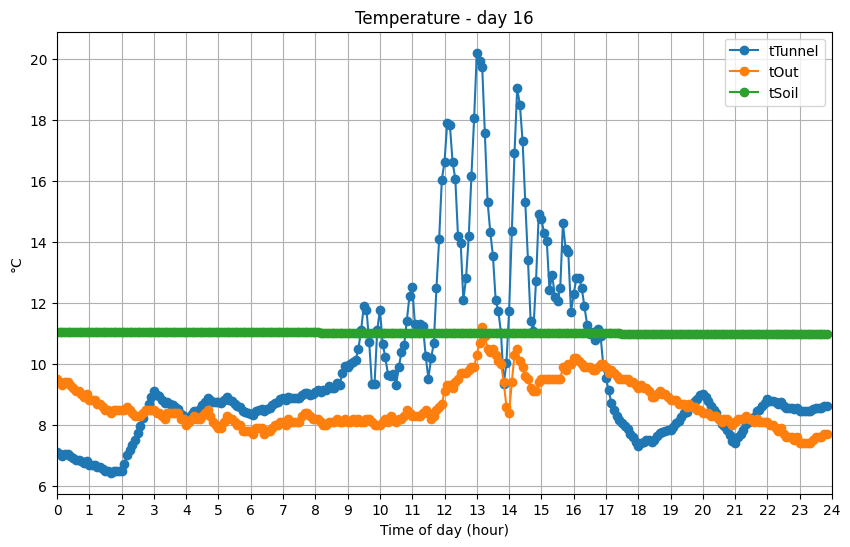

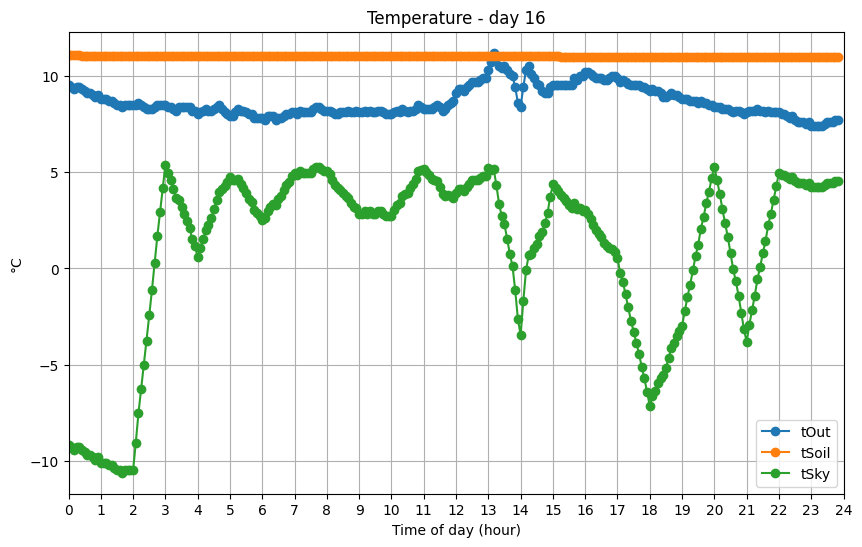

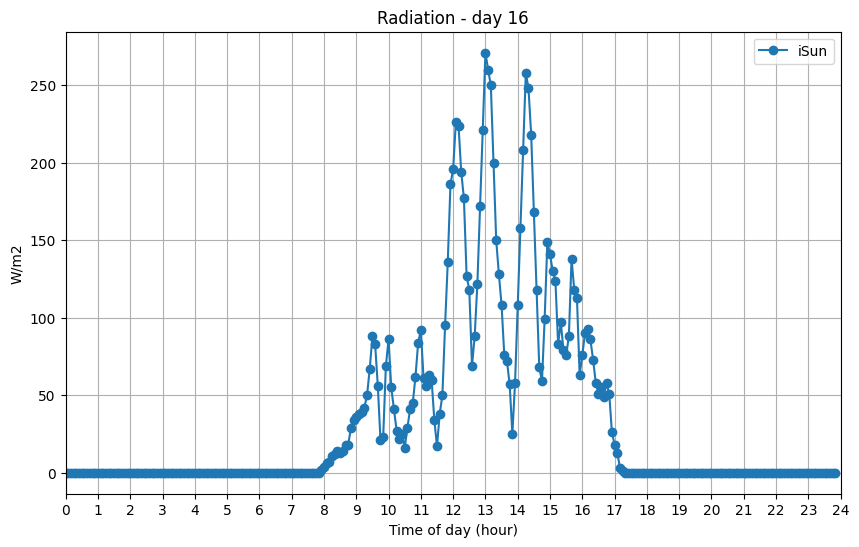

In [7]:
""" Zoom in """
def display_zoomed_output(output_df, day, chosen_vars, titles, ylabels, style, axes=None):  
    zoomed_output = output_df.copy()
    zoomed_output.columns = output_df.columns.get_level_values(0)
    zoomed_output = zoomed_output[zoomed_output["Time"] >= (day-1) * 24 * 60 * 60]
    zoomed_output = zoomed_output[zoomed_output["Time"] < day * 24 * 60 * 60]

    if axes is None:
        axes = [None] * len(titles)
        
    returned_axes = []
    for vars_to_plot, title, ylabel, ax in zip(chosen_vars, titles, ylabels, axes):
        if ax is None:
            fig = plt.figure(figsize=(10, 6))
            ax = fig.add_subplot(111)
        else:
            ax = ax
        
        for var in vars_to_plot:
            ax.plot((zoomed_output["Time"]/3600)%24, 
                    zoomed_output[var], 
                    style, 
                    label=var)
        
        ax.set_xlabel("Time of day (hour)")
        ax.set_xticks(np.arange(0, 25, step=1))
        ax.set_xlim([0, 24])
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} - day {day}")
        ax.legend()
        ax.grid(True)
        returned_axes.append(ax)

    return returned_axes

axes = display_zoomed_output(output_2, 
                      day=16, 
                      chosen_vars=[["tTunnel", "tOut", "tSoil"], ["tOut", "tSoil", "tSky"], ["iSun"]], 
                      titles=["Temperature", "Temperature", "Radiation"], 
                      ylabels=["°C", "°C", "W/m2"], 
                      style='-o')

### 4.2.1 Exercise: critical reflection on model output

Examine the model output above and critically reflect: is this output reasonable? 

The following questions may help you refine your answer:
- What is happening to `tTunnel` between 13:00 and 14:00?
- What is causing this?
- Is that something we can expect in a real greenhouse?

#### 4.2.1 Solution

Run the next piece of code to see the graphs generated to answer this question.

Looking at the weather data, we see that this is a winter day in a high latitude: the sun is shining between 8:00 in the morning and 17:00 in the afternoon (9 hours of light). The outdoor temperatures are between 7-12°C, and solar radiation goes up to 250 W/m2.

In the afternoon (12:00-15:00), clouds are passing under the sun. We see relatively fast fluctuations from high to low radiation levels. Especially between 13:00 and 14:00, we see a drop in radiation from 250 W/m2 to around 30 W/m2. As a result, the outside temperature drops by about 2.5 °C: from 11 °C to 8.5 °C. The sky temperature also drops considerably, from around 5 °C to -3 °C.

Based on the above, the model calculates a considerable drop in the tunnel temperature: from 20 °C at 13:00 to around 9.5 °C at 14:00. It is remarkable that the tunnel temperature drops by 10°C, while the drop in outdoor temperature is considerably smaller. The drop in sky temperature is also smaller. This means that the main driver for this calculated sudden drop in temperatures is the difference in solar radiation, which is the main component heating the greenhouse in this model.

However, such a fast drop in temperature seems unreasonable. In an actual greenhouse, especially with no ventilation, the fluctuations in temperature are typically much slower. One main reason is that the greenhouse construction itself, and especially the soil under it, operate as a heat buffer, which slowly absorbs and releases solar energy. 

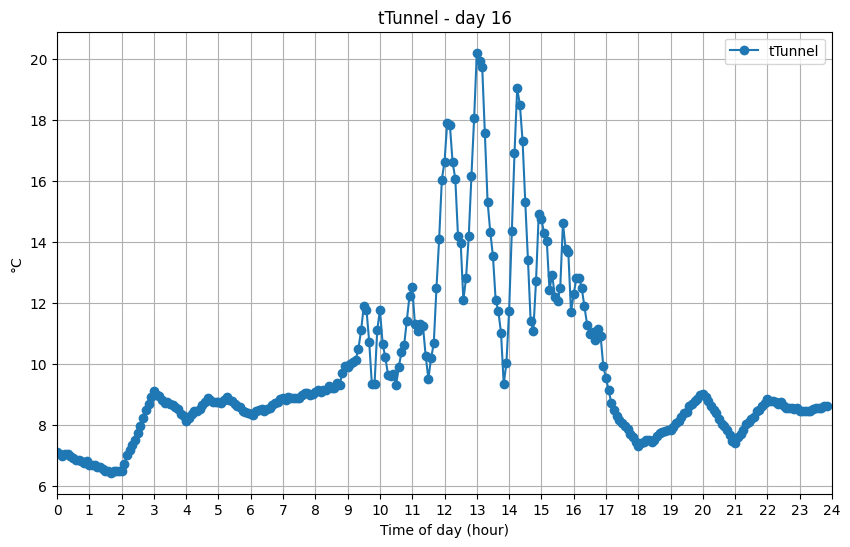

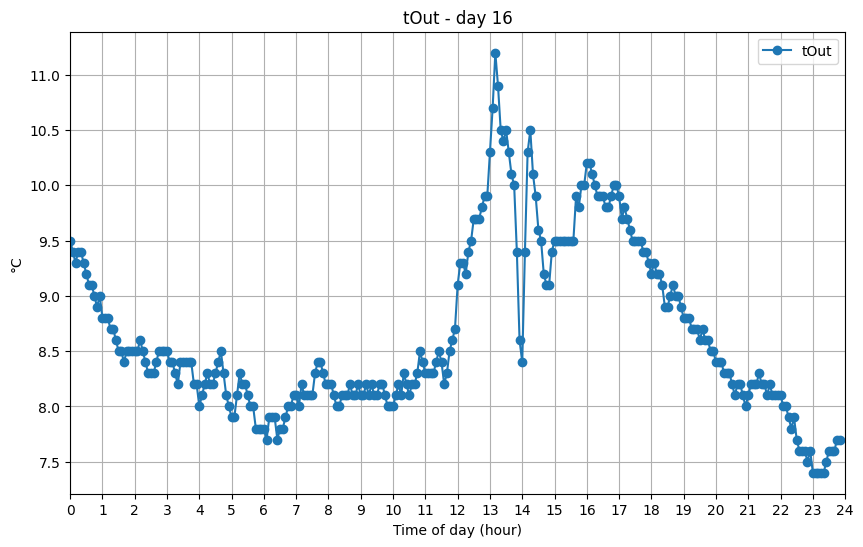

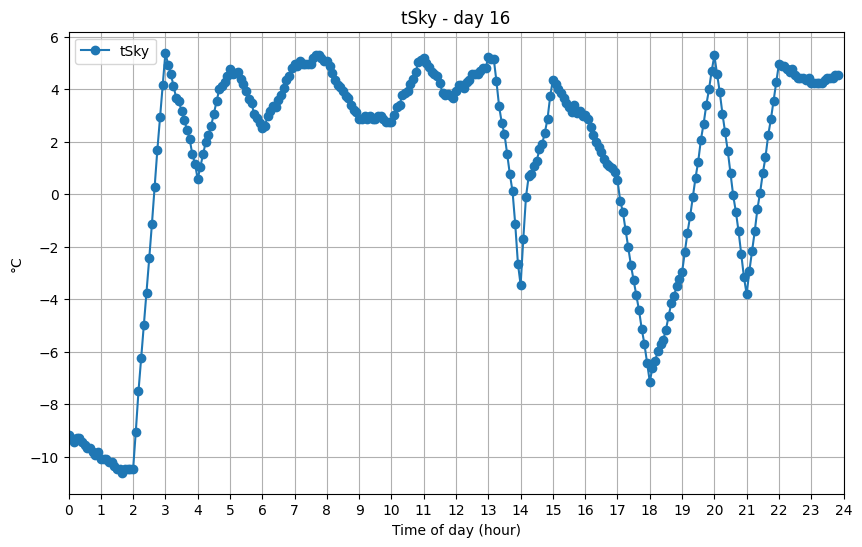

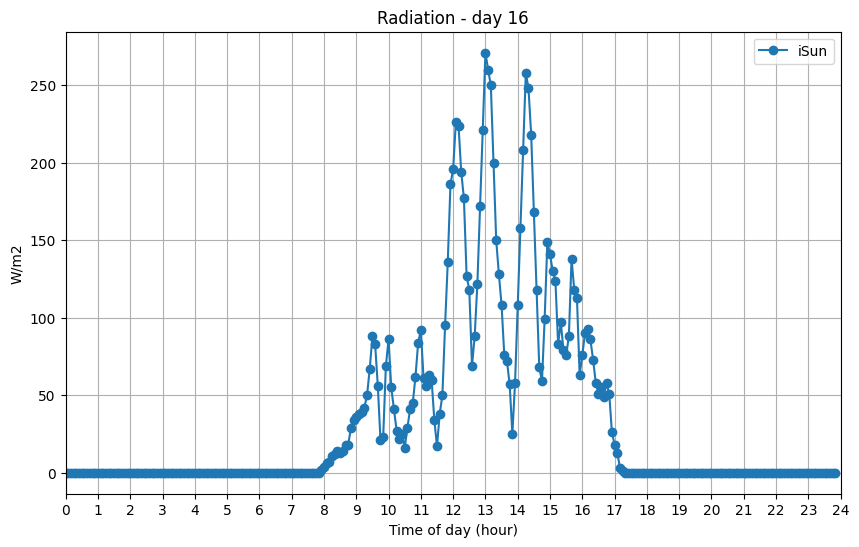

In [8]:
axes = display_zoomed_output(output_2, 
                      day=16, 
                      chosen_vars=[["tTunnel"], ["tOut"], ["tSky"], ["iSun"]], 
                      titles=["tTunnel", "tOut", "tSky", "Radiation"], 
                      ylabels=["°C", "°C", "°C", "W/m2"], 
                      style='-o')

## 4.3 A dynamic tunnel model

Explain why this isn't good enough

Make a new model

In [40]:
""" 
Solution 3.2.1
Define tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "6",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "5",
        "type": "const"
    }
}

"""
Add the variable tTunnel to the tunnel model definition tunnel_def
"""
tunnel_def["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=tunnel_def, 
    output_path=os.path.join("output", "output.csv")
)
mdl.load()
model_table(mdl)

Variable,Type,Definition
tau,const,0.7
iSun,aux,700
fTunnelSky,const,0.5
epsCover,const,1
alphaR,const,6
tSky,aux,0
tOut,aux,30
tSoil,aux,35
fTunnelSoil,const,0.5
epsSoil,const,1


In [50]:
# A guess at capacity:
# The air has a capacity of 1200 J/m3/K (Stanghellini textbook)
# Soil has a capacity of 1.73e6 J/m3/K (Vanthoor)
# Per m2 assume we consider 2.5 m of air and 0.1 m of soil, that gives:
# 1200x(2.5/2.6) + 1.73e6 (0.1/2.6) = 1153 + 66538 = 67691

tunnel_def["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "state",
        "init": "8",
        "definition": "1/(67691)*(" \
        "tau * iSun " \
        "- fTunnelSky * epsCover * alphaR * (tTunnel - tSky) " \
        "- aCoverOverSoil * alphaCover * (tTunnel - tOut) " \
        "- fTunnelSoil * epsSoil * alphaR * (tTunnel - tSoil) " \
        "- alphaSoil * (tTunnel - tSoil)"
    ")"
    }

options = {
    "options": {
        "t_start":"0",
        "t_end": str(16 * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

mdl_3 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_def, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_3.csv")
)

mdl_3.load()
model_table(mdl_3)



Loading model from input\example_weather.csv


Variable,Type,Definition
tau,const,0.7
iSun,input,iSun
fTunnelSky,const,0.5
epsCover,const,1
alphaR,const,6
tSky,input,tSky
tOut,input,tOut
tSoil,input,tSoil
fTunnelSoil,const,0.5
epsSoil,const,1


In [51]:
""" Run the model """
mdl_3.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-08-11T14:15:10.654082
Running: 100.00%

Simulation complete at time (ISO format): 2026-08-11T14:15:11.796349
Simulated 15.996527777777779 days
Elapsed time: 1.1422669887542725 seconds
Output saved to file output\output_3.csv
Model structure log saved to output\output_3_model_struct_log.json
Simulation log saved to output\output_3_simulation_log.txt


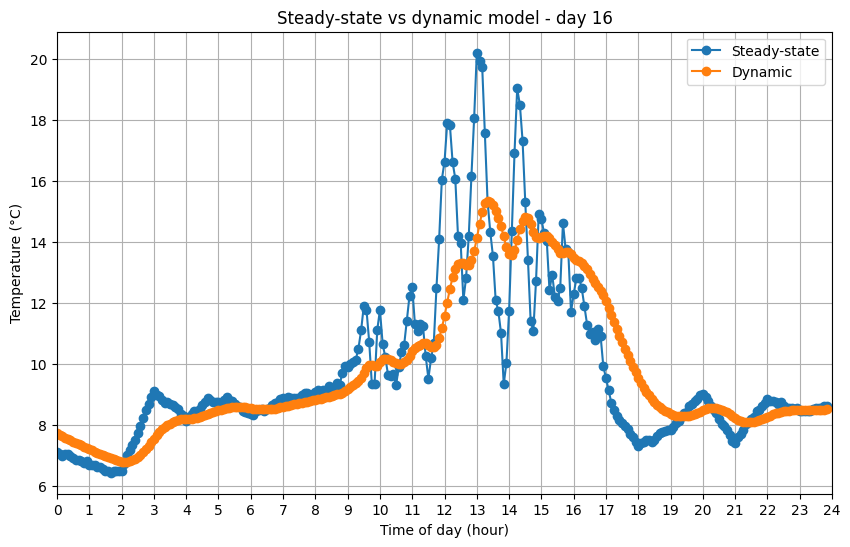

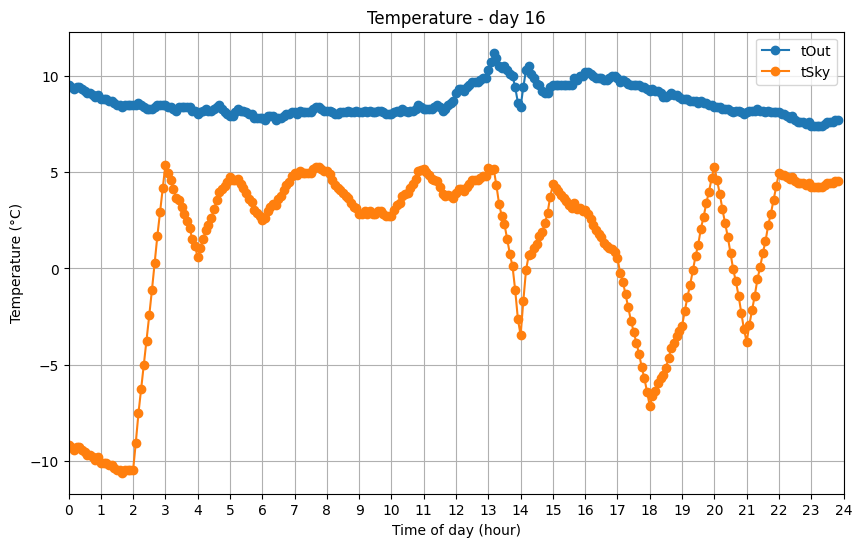

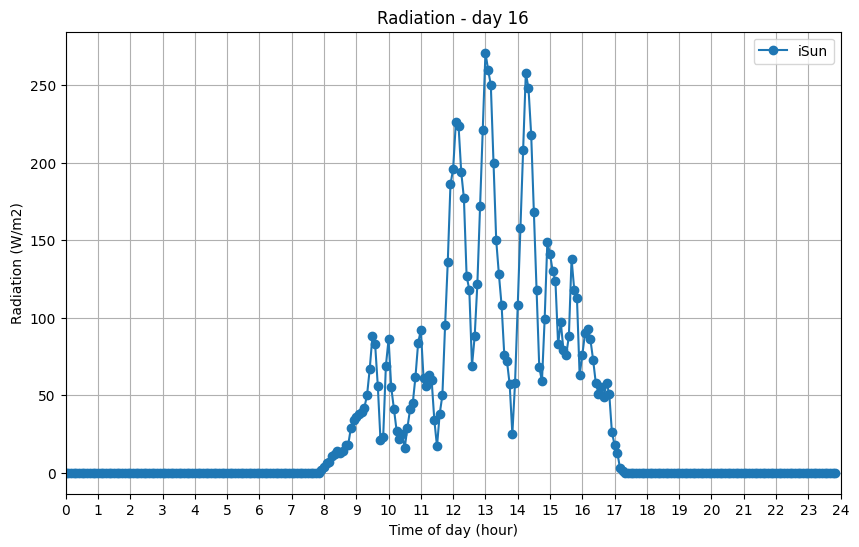

In [52]:
"""Load simulation result"""
output_3 = pd.read_csv(os.path.join("output", "output_3.csv"), header=[0,1,2], low_memory=False)

"""Make graphs"""
day = 16
axes = display_zoomed_output(output_2, 
                      day=day, 
                      chosen_vars=[["tTunnel"], ["tOut", "tSky"], ["iSun"]], 
                      titles=["Temperature", "Temperature", "Radiation"], 
                      ylabels=["Temperature (°C)", "Temperature (°C)", "Radiation (W/m2)"], 
                      style='-o')

axes = display_zoomed_output(output_3, 
                      day=day, 
                      chosen_vars=[["tTunnel"]], 
                      titles=["Temperature"], 
                      ylabels=["Temperature (°C)"], 
                      style='-o',
                      axes=axes)

axes[0].set_title(f"Steady-state vs dynamic model - day {day}")
axes[0].legend(["Steady-state", "Dynamic"]);

### 4.3.1 Exercise

- Change the heat capacity and see what happens

```{note}
Books are usually written on paper ... But Jupyter Book can create _websites_!
```

If you sold 100 books at \$10 per book, you'd have \$1000 dollars according to [](#eq:book). If instead you publish your Jupyter Book to the web for free, you'd have \$0 dollars!

:::{math}
:name: eq:book

x \times y = z
:::
